# Bloc 1 — Analyse exploratoire (EDA, cours 1)
**Fichiers (Health, partie clinique)** : `clinical_encounters`, `clinical_notes`, `clinical_observation`, `clinical_procedures`, `patient_administration` (versions `_cleaned`, produites par `cleaning.ipynb`).

Le nettoyage (doublons, formats, catégories, manquants) est fait dans `cleaning.ipynb`. Ce notebook décrit les données nettoyées :
1. **Typage** de chaque variable (identifiant, date, numérique discrète ou continue, nominale ordonnée ou non, texte libre) et **transformation des dates** en durées ou en années.
2. **Variables numériques** : moyenne ± écart-type, médiane, min, max, quartiles, histogramme, boxplot ou violon, et comparaison à une loi normale ou à une loi de puissance.
3. **Variables nominales** : barplot de la répartition.
4. **Corrélations** de Pearson et de Spearman, visualisation des paires corrélées. Rappel : corrélation n'est pas causalité.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
pd.set_option('display.width', 200)
chemin = 'cleaned/'

enc = pd.read_csv(chemin + 'clinical_encounters_cleaned.csv', parse_dates=['encounter_start', 'encounter_end', 'follow_up_date'])
notes = pd.read_csv(chemin + 'clinical_notes_cleaned.csv', parse_dates=['document_date'])
obs = pd.read_csv(chemin + 'clinical_observation_cleaned.csv', parse_dates=['observation_time'])
proc = pd.read_csv(chemin + 'clinical_procedures_cleaned.csv', parse_dates=['scheduled_time', 'performed_time', 'next_review_date'])
pat = pd.read_csv(chemin + 'patient_administration_cleaned.csv', parse_dates=['date_of_birth', 'registration_date'])
tables = {'clinical_encounters': enc, 'clinical_notes': notes, 'clinical_observation': obs,
          'clinical_procedures': proc, 'patient_administration': pat}
for nom, df in tables.items():
    print(f'{nom:24s} {df.shape}')

clinical_encounters      (1067, 12)
clinical_notes           (30, 10)
clinical_observation     (17734, 14)
clinical_procedures      (310, 14)
patient_administration   (240, 10)


## 1. Typage des variables
Règle appliquée : une colonne `datetime` est une **date** ; une colonne dont le nom finit par `_number`, `_id`, `_license` ou `_reference` (ou qui contient `license_number`) est un **identifiant** (on ne calcule pas de statistiques dessus) ; un texte de plus de 50 modalités est du **texte libre** ; les autres textes sont **nominaux**. Trois nominales ont un ordre naturel et sont typées **ordonnées** : `confidentiality_class` (standard < confidential < restricted), `quality_code` et `interpretation_code` (du « dans la norme » au « à revoir »). Une colonne numérique est **discrète** si toutes ses valeurs sont entières et qu'elle a moins de 30 valeurs distinctes, **continue** sinon.

In [2]:
ORDONNEES = {'confidentiality_class', 'quality_code', 'interpretation_code'}

def type_variable(s):
    nom = s.name
    if pd.api.types.is_datetime64_any_dtype(s):
        return 'date'
    if nom.endswith(('_number', '_id', '_license', '_reference')) or 'license_number' in nom:
        return 'identifiant'
    if pd.api.types.is_numeric_dtype(s):
        v = s.dropna()
        return 'numérique discrète' if (v % 1 == 0).all() and v.nunique() < 30 else 'numérique continue'
    if s.nunique() > 50:
        return 'texte libre'
    return 'nominale ordonnée' if nom in ORDONNEES else 'nominale non ordonnée'

typage = pd.concat([pd.DataFrame({'table': nom, 'variable': df.columns,
                                  'type': [type_variable(df[c]) for c in df.columns],
                                  'nb_modalites': [df[c].nunique() for c in df.columns],
                                  'manquants_%': (df.isna().mean() * 100).round(1).values})
                    for nom, df in tables.items()], ignore_index=True)
print(typage.groupby('type').size())
typage

type
date                     10
identifiant              22
nominale non ordonnée    21
nominale ordonnée         4
numérique continue        1
texte libre               2
dtype: int64


,table,variable,type,nb_modalites,manquants_%
0,clinical_encounters,encounter_number,identifiant,1067,0.0
1,clinical_encounters,patient_number,identifiant,240,0.0
2,clinical_encounters,encounter_start,date,998,0.0
3,clinical_encounters,encounter_end,date,1065,0.0
4,clinical_encounters,facility_license_number,identifiant,3,0.0
5,clinical_encounters,encounter_type,nominale non ordonnée,10,0.0
6,clinical_encounters,referral_source,nominale non ordonnée,6,0.0
7,clinical_encounters,attending_license_number,identifiant,8,0.0
8,clinical_encounters,service_unit,nominale non ordonnée,6,0.0
9,clinical_encounters,disposition,nominale non ordonnée,4,0.0


**Remarques**
- Aucune variable n'est numérique au départ, sauf `numeric_value` (observations) : c'est une **variable « longue »** (une ligne = une mesure), dont le sens dépend de `observation_code`. Elle se décrit donc **par type de mesure** (section 3).
- `text_value` (observations) a 8 modalités qualitatives (`normal`, `inconclusive`, `mild`...) : nominale.
- `occupation_text` (patients) dépasse 50 modalités : texte libre, mais elle porte une information forte (professions dirigeantes), reprise au bloc 7.
- `follow_up_date` et `next_review_date` ont des manquants (pas de suivi prévu) : laissés en `NaT`, comme au nettoyage.

## 2. Transformation des dates en durées ou en années
Les dates brutes ne se comparent pas entre elles ; on construit des variables numériques interprétables.

In [3]:
enc['duree_min'] = (enc.encounter_end - enc.encounter_start).dt.total_seconds() / 60
enc['delai_suivi_j'] = (enc.follow_up_date - enc.encounter_end.dt.normalize()).dt.days
enc['annee'] = enc.encounter_start.dt.year

proc['retard_min'] = (proc.performed_time - proc.scheduled_time).dt.total_seconds() / 60
proc['delai_revue_j'] = (proc.next_review_date - proc.performed_time.dt.normalize()).dt.days
proc['annee'] = proc.performed_time.dt.year

pat['age_inscription'] = (pat.registration_date - pat.date_of_birth).dt.days / 365.25
pat['annee_naissance'] = pat.date_of_birth.dt.year
pat['annee_inscription'] = pat.registration_date.dt.year
pat['nb_consultations'] = pat.patient_number.map(enc.groupby('patient_number').size()).fillna(0).astype(int)

notes['nb_mots'] = notes.text.str.split().str.len()
notes = notes.merge(enc[['encounter_number', 'encounter_start']], on='encounter_number', how='left')
notes['delai_note_j'] = (notes.document_date - notes.encounter_start.dt.normalize()).dt.days

print('Jour du mois des inscriptions :', pat.registration_date.dt.day.value_counts().to_dict())

Jour du mois des inscriptions : {1: 239, 9: 1}


**Artefact de génération repéré dès ici** : 239 inscriptions sur 240 tombent le **1er du mois**. Une date d'inscription n'a donc qu'une précision mensuelle ; on ne l'utilisera pas au jour près (bloc 5).

## 3. Variables numériques
Pour chaque variable : moyenne ± écart-type, médiane, min, max, quartiles, histogramme et boxplot. Pour juger de la loi :
- **loi normale** : test de D'Agostino-Pearson (`scipy.stats.normaltest`, H0 = normalité) et coefficient d'asymétrie ;
- **loi de puissance** : pour une variable positive à queue lourde, la fonction de survie (CCDF) devient une droite en échelle log-log. On le vérifie sur les variables de comptage.

In [4]:
def resume_numerique(df, cols, nom):
    lignes = []
    for c in cols:
        v = df[c].dropna()
        p = stats.normaltest(v).pvalue if len(v) >= 20 else np.nan
        lignes.append({'table': nom, 'variable': c, 'n': len(v), 'moyenne': v.mean(), 'ecart_type': v.std(),
                       'min': v.min(), 'Q1': v.quantile(.25), 'mediane': v.median(), 'Q3': v.quantile(.75),
                       'max': v.max(), 'asymetrie': stats.skew(v), 'p_normalite': p,
                       'loi': 'compatible normale' if p > 0.05 else 'non normale'})
    return pd.DataFrame(lignes).round(2)

def histo_box(df, cols, titre):
    fig, axes = plt.subplots(2, len(cols), figsize=(4 * len(cols), 6), gridspec_kw={'height_ratios': [3, 1]})
    axes = np.array(axes).reshape(2, -1)
    for j, c in enumerate(cols):
        sns.histplot(df[c].dropna(), bins=30, ax=axes[0, j]); axes[0, j].set_title(c)
        sns.boxplot(x=df[c].dropna(), ax=axes[1, j])
    fig.suptitle(titre); plt.tight_layout(); plt.show()

num = pd.concat([
    resume_numerique(enc, ['duree_min', 'delai_suivi_j'], 'clinical_encounters'),
    resume_numerique(proc, ['retard_min', 'delai_revue_j'], 'clinical_procedures'),
    resume_numerique(pat, ['age_inscription', 'annee_naissance', 'nb_consultations'], 'patient_administration'),
    resume_numerique(notes, ['nb_mots', 'delai_note_j'], 'clinical_notes')])
num

,table,variable,n,moyenne,ecart_type,min,Q1,mediane,Q3,max,asymetrie,p_normalite,loi
0,clinical_encounters,duree_min,1067,87.67,34.58,50.00,66.00,82.00,101.00,240.00,2.61,0.00,non normale
1,clinical_encounters,delai_suivi_j,827,388.39,172.70,9.00,294.00,396.00,495.50,1181.00,0.12,0.01,non normale
0,clinical_procedures,retard_min,310,1110.61,15244.13,10.00,10.00,10.00,10.00,254890.00,15.49,0.00,non normale
1,clinical_procedures,delai_revue_j,254,339.94,190.45,28.00,173.25,363.00,472.00,807.00,-0.02,0.02,non normale
0,patient_administration,age_inscription,240,48.72,15.80,15.27,36.11,47.97,61.55,79.51,-0.15,0.00,non normale
1,patient_administration,annee_naissance,240,1970.14,15.99,1935.00,1957.00,1971.00,1982.25,2003.00,0.11,0.00,non normale
2,patient_administration,nb_consultations,240,4.45,1.17,3.00,4.00,4.00,5.00,11.00,1.77,0.00,non normale
0,clinical_notes,nb_mots,30,179.23,47.96,122.00,125.00,180.00,184.00,269.00,0.46,0.30,compatible normale
1,clinical_notes,delai_note_j,30,481.87,885.24,-1249.00,-41.00,292.50,956.00,2670.00,0.41,0.46,compatible normale


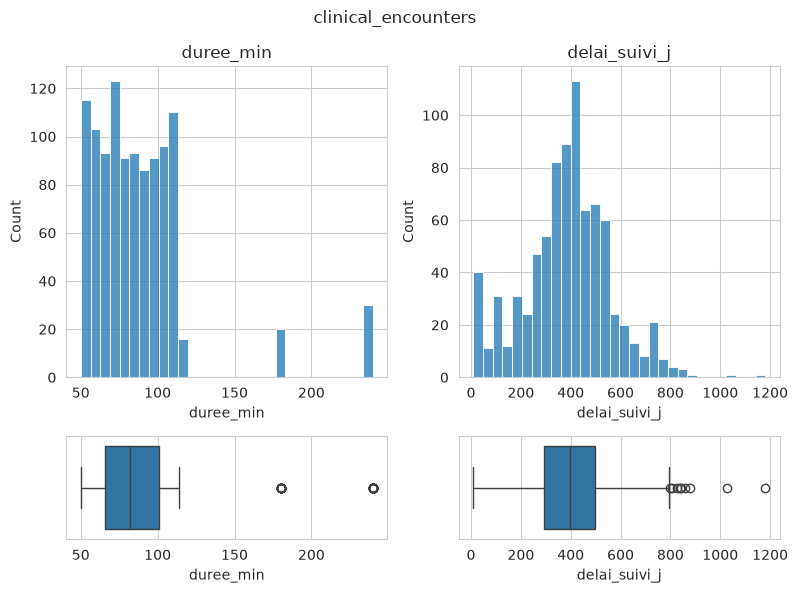

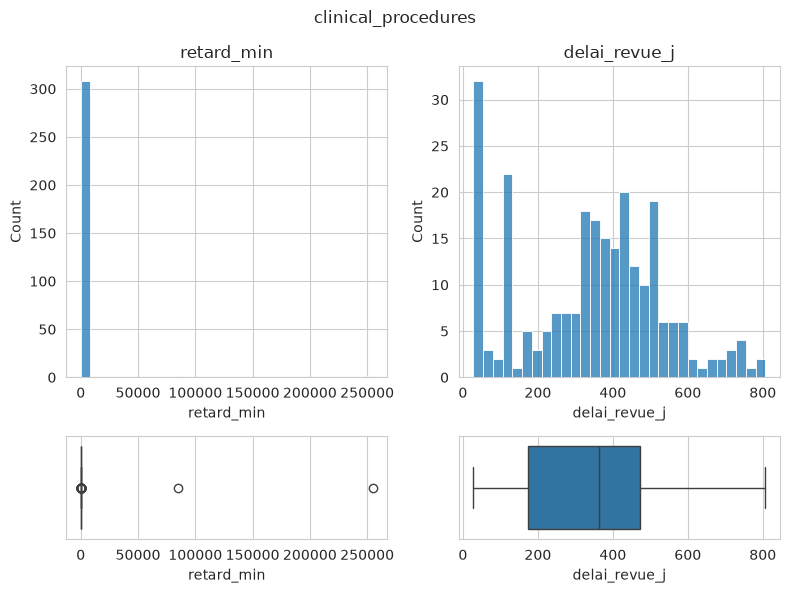

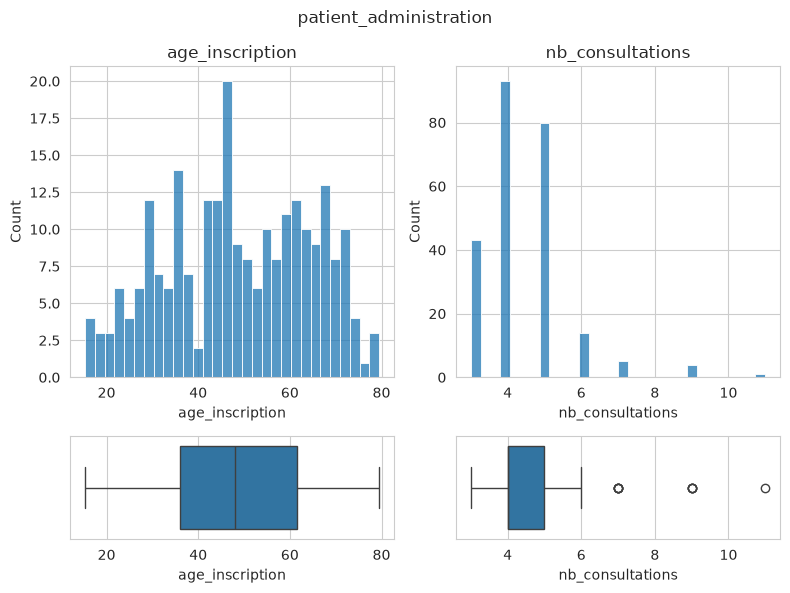

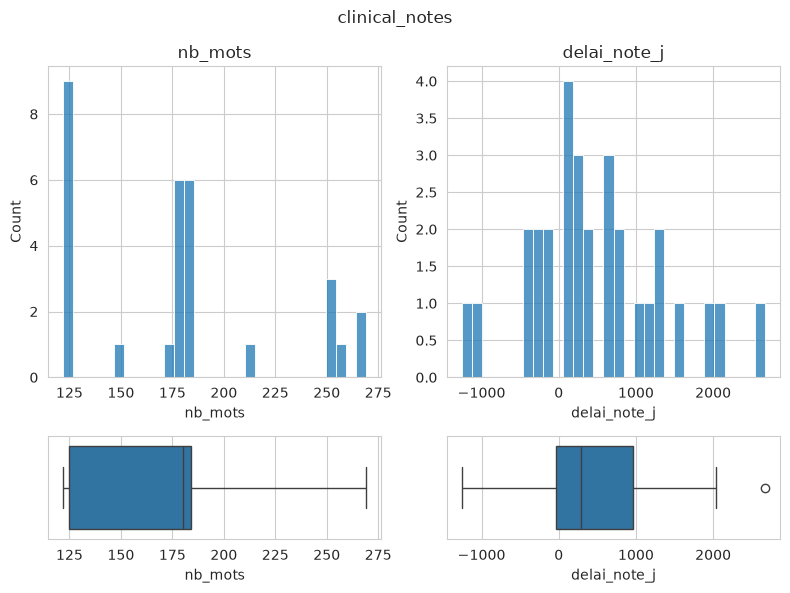

In [5]:
histo_box(enc, ['duree_min', 'delai_suivi_j'], 'clinical_encounters')
histo_box(proc, ['retard_min', 'delai_revue_j'], 'clinical_procedures')
histo_box(pat, ['age_inscription', 'nb_consultations'], 'patient_administration')
histo_box(notes, ['nb_mots', 'delai_note_j'], 'clinical_notes')

**Lecture**
- **Durée des consultations** : distribution multimodale, pas normale. L'essentiel est entre 50 et 114 min, puis deux pics isolés à **180 et 240 min** (les 50 consultations `research_procedure` et `specialist_procedure`, cf. bloc 3).
- **Retard des procédures** : une valeur domine (10 min) ; le boxplot écrase tout le reste. La distribution est dégénérée, ce qui explique que l'IQR soit nul au bloc 3.
- **Âge à l'inscription** : symétrique (asymétrie ≈ −0,15) mais trop plate pour une loi normale (test rejeté) : les âges sont répartis presque uniformément de 15 à 80 ans, ce qui ressemble à un tirage de génération plutôt qu'à une vraie patientèle.
- Seules les deux variables de `clinical_notes` passent le test de normalité, mais avec 30 notes le test a très peu de puissance : on ne conclut rien.
- **Nombre de consultations par patient** : discret (3 à 11), concentré sur 4. On teste la loi de puissance juste en dessous.
- **Délai note − consultation** : centré positif mais avec des valeurs **négatives** (note écrite avant la consultation), déjà signalées au bloc 3.

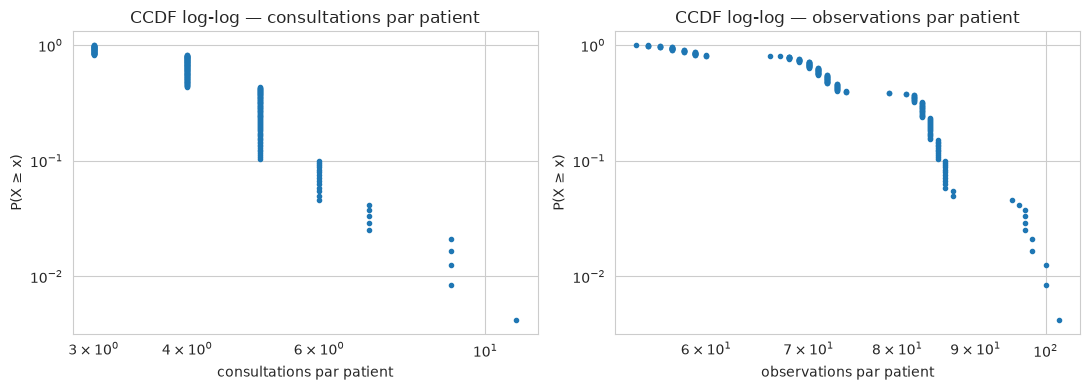

In [6]:
# Loi de puissance ? CCDF en log-log pour les comptages
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (serie, nom) in zip(axes, [(pat.nb_consultations, 'consultations par patient'),
                                    (obs.groupby('patient_number').size(), 'observations par patient')]):
    v = np.sort(serie.values)
    ccdf = 1 - np.arange(len(v)) / len(v)
    ax.loglog(v, ccdf, 'o', ms=3)
    ax.set_xlabel(nom); ax.set_ylabel('P(X ≥ x)'); ax.set_title(f'CCDF log-log — {nom}')
plt.tight_layout(); plt.show()

Les deux CCDF **chutent brutalement** au lieu de suivre une droite : il n'y a pas de queue lourde, donc **pas de loi de puissance**. Le nombre de consultations est fixé par le protocole de suivi (3 à 5 visites), pas par un mécanisme d'attachement préférentiel. Les rares patients à 7-11 consultations sont justement ceux qui reçoivent `MRP-42` (bloc 3), ce qui en fait un indice et non une queue de distribution.

### 3.1 `numeric_value` par type de mesure
27 types de mesures, chacun avec son unité. On résume chaque type séparément.

In [7]:
par_code = (obs.dropna(subset=['numeric_value'])
               .groupby(['observation_code', 'unit']).numeric_value
               .agg(n='count', moyenne='mean', ecart_type='std', min='min',
                    Q1=lambda v: v.quantile(.25), mediane='median', Q3=lambda v: v.quantile(.75), max='max'))
par_code['p_normalite'] = obs.dropna(subset=['numeric_value']).groupby('observation_code').numeric_value.apply(lambda v: stats.normaltest(v).pvalue).values
par_code.round(2)

,,n,moyenne,ecart_type,min,Q1,mediane,Q3,max,p_normalite
observation_code,unit,,,,,,,,,
agecond,count,240,0.98,0.91,0.00,0.00,1.00,2.00,4.00,0.00
apical,bpm,1017,77.08,12.12,42.00,68.60,76.30,85.10,106.70,0.02
balance,index,947,76.40,12.96,38.90,67.90,76.80,85.20,100.00,0.00
bioage,years,934,49.70,16.28,11.50,38.02,51.50,62.60,88.30,0.00
cammatch,index,240,89.38,9.36,40.60,84.82,91.25,95.80,100.00,0.00
cardout,l/min,941,5.47,1.01,3.00,4.80,5.38,6.07,9.60,0.00
cognitive,index,948,86.32,8.59,57.20,81.20,87.10,92.60,100.00,0.00
cvrisk,index,240,42.23,12.06,6.40,33.90,41.80,50.52,76.90,1.00
diabp,mmhg,240,74.88,8.19,52.70,69.57,75.20,80.00,96.10,0.54


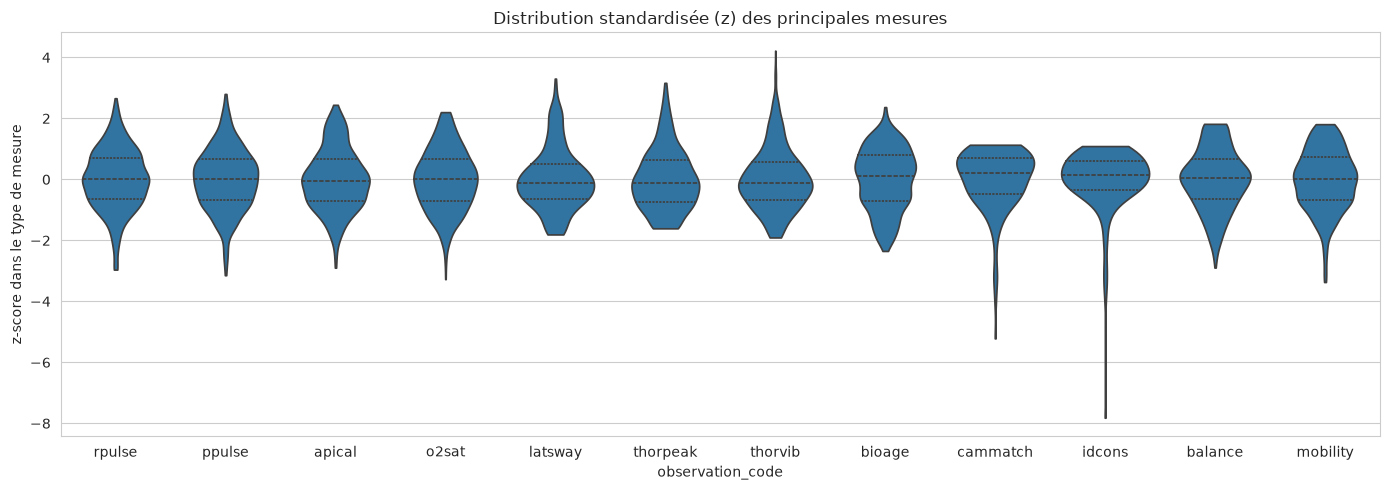

In [8]:
codes = ['rpulse', 'ppulse', 'apical', 'o2sat', 'latsway', 'thorpeak', 'thorvib', 'bioage', 'cammatch', 'idcons', 'balance', 'mobility']
fig, ax = plt.subplots(figsize=(14, 5))
sub = obs[obs.observation_code.isin(codes)]
# standardisation par code pour mettre des unités différentes sur un même axe
sub = sub.assign(z=sub.groupby('observation_code').numeric_value.transform(lambda v: (v - v.mean()) / v.std()))
sns.violinplot(data=sub, x='observation_code', y='z', order=codes, inner='quartile', cut=0, ax=ax)
ax.set_title('Distribution standardisée (z) des principales mesures'); ax.set_ylabel('z-score dans le type de mesure')
plt.tight_layout(); plt.show()

**Lecture**
- Les pouls (`rpulse`, `ppulse`, `apical`) et la saturation sont unimodaux. Avec ~1 000 valeurs le test de normalité rejette au moindre écart ; seules 8 mesures sur 27 le passent (pressions artérielles, volume d'éjection, acuités visuelles, vitesse de marche, pouls périphérique, inflammation). On regarde donc surtout la forme.
- `latsway`, `thorpeak` et `thorvib` sont **asymétriques à droite** avec une petite bosse haute ; `cammatch` et `idcons` sont asymétriques **à gauche** (quelques scores de reconnaissance très bas). Ce sont les mêmes variables que les notes cliniques associent au « phénotype » (balancement, seconde structure thoracique, discordance caméra), cf. blocs 6 et 7.

## 4. Variables nominales

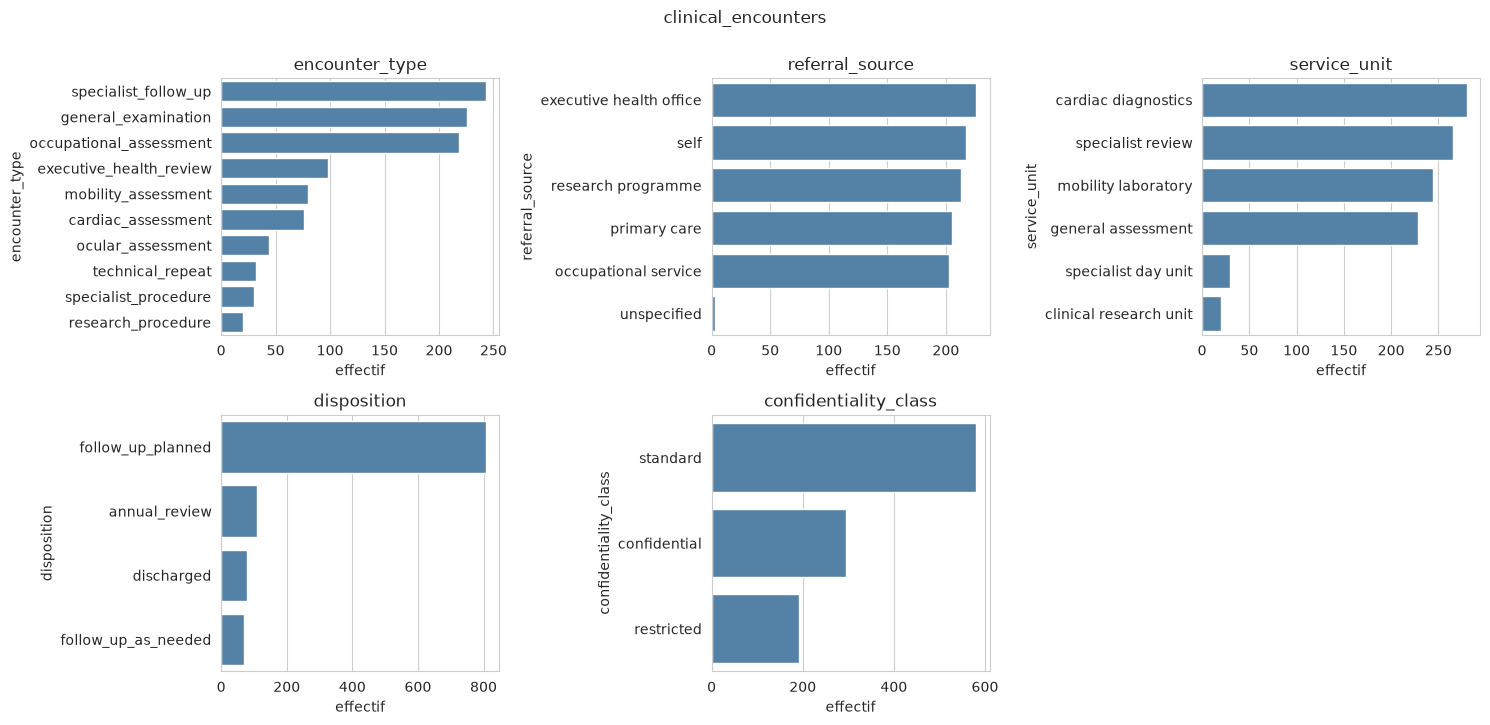

/tmp/ipykernel_2793/969525644.py:15: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.suptitle(nom, y=1.0); plt.tight_layout(); plt.show()




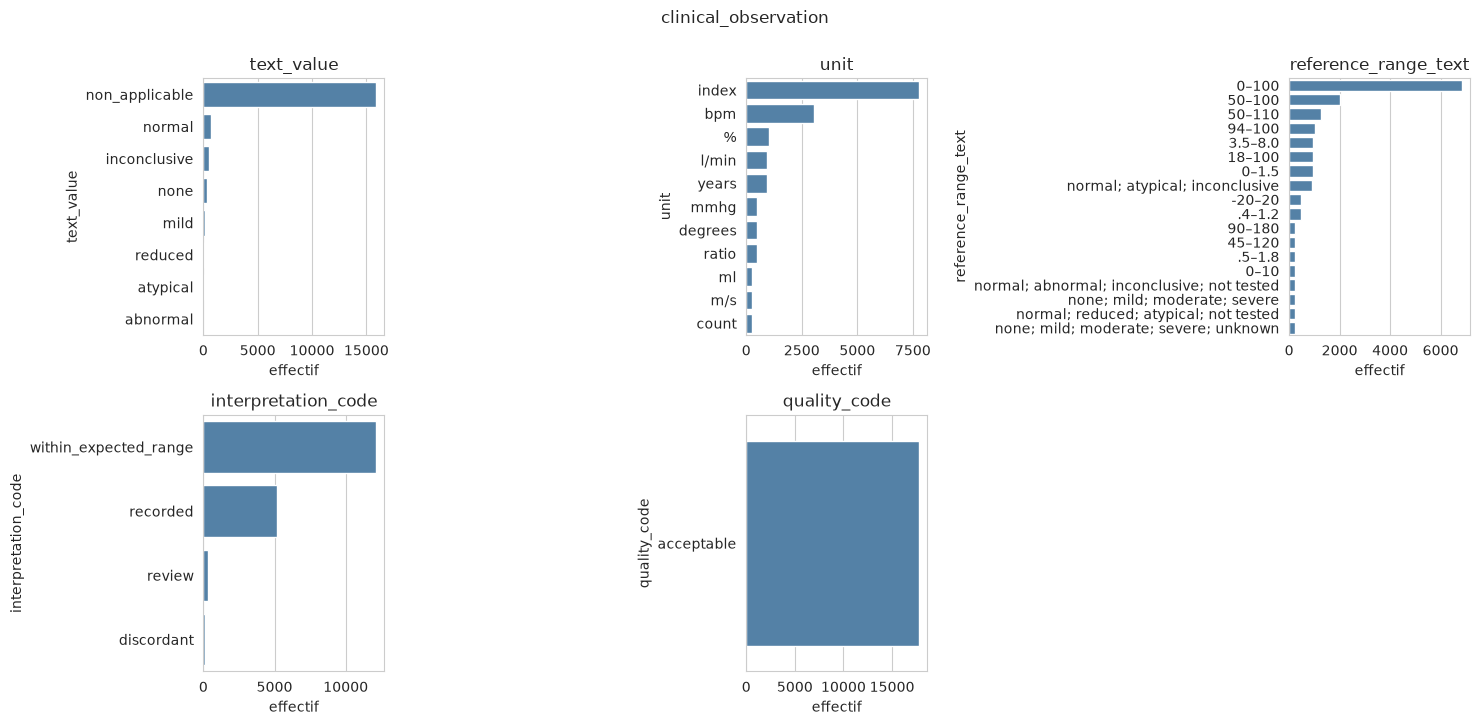

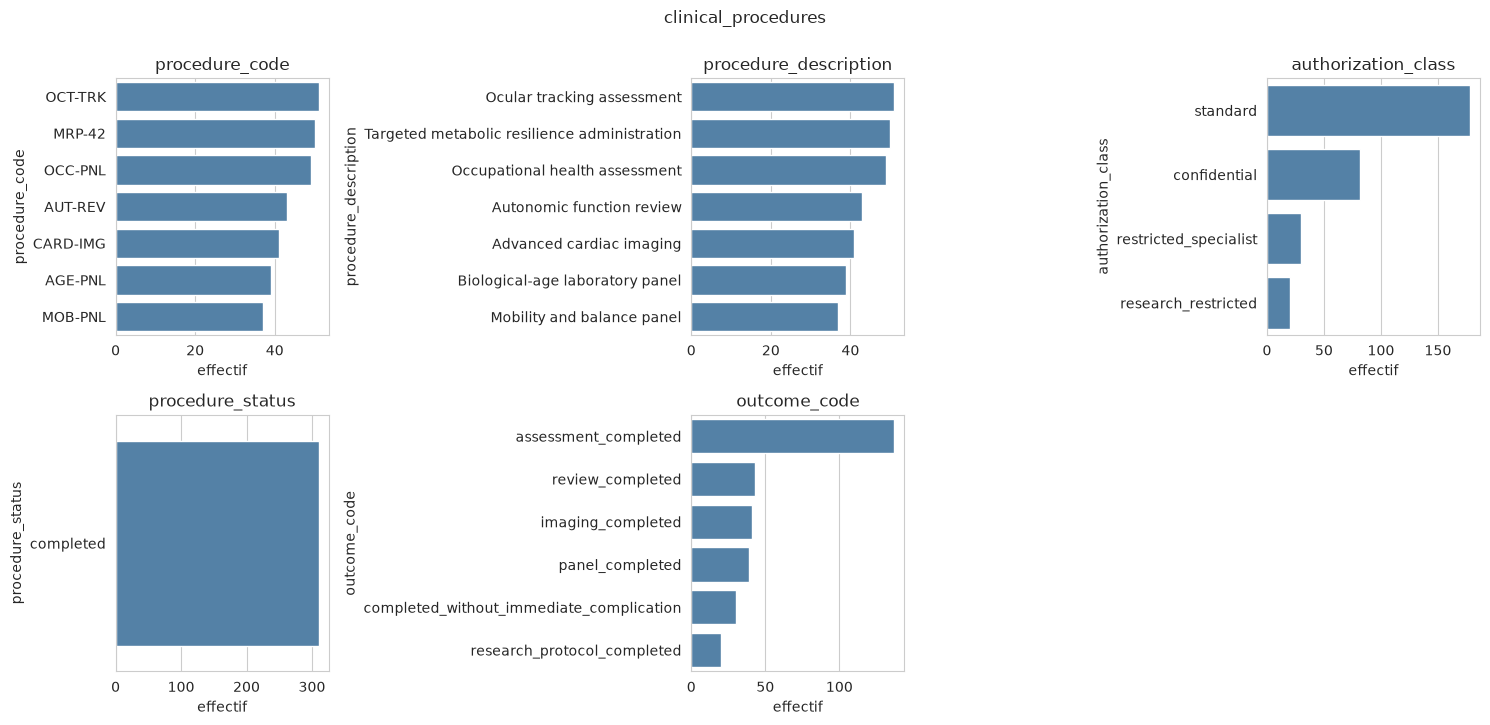

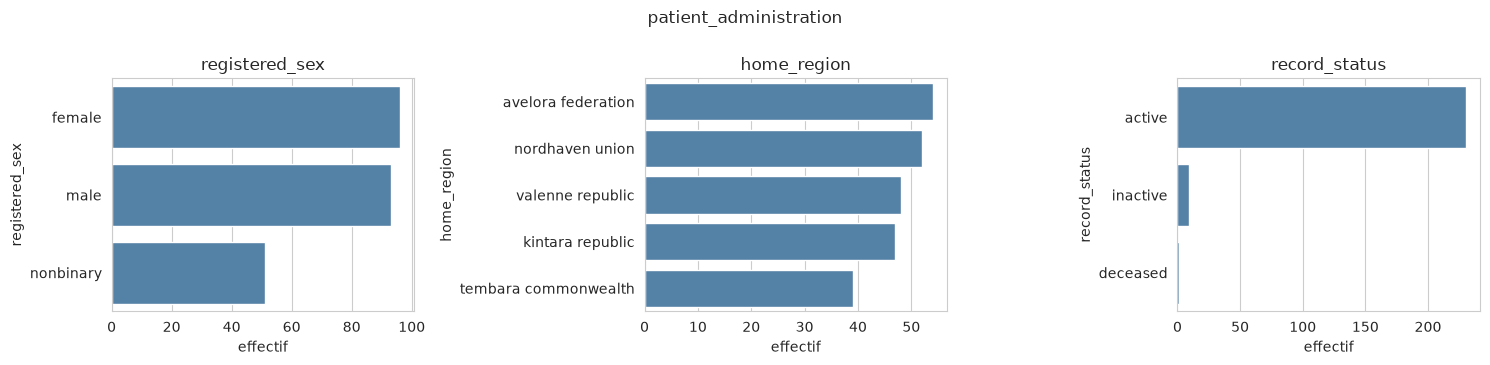

In [9]:
nominales = typage[typage.type.str.startswith('nominale') & (typage.nb_modalites <= 30)]
for nom, df in tables.items():
    cols = nominales[nominales.table == nom].variable.tolist()
    if not cols:
        continue
    n = len(cols); ncol = 3; nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.6 * nrow))
    axes = np.array(axes).ravel()
    for ax, c in zip(axes, cols):
        vc = df[c].value_counts()
        sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color='steelblue')
        ax.set_title(c); ax.set_xlabel('effectif')
    for ax in axes[n:]:
        ax.axis('off')
    fig.suptitle(nom, y=1.0); plt.tight_layout(); plt.show()

**Lecture**
- `clinical_encounters` : 10 types de consultation ; `research_procedure` (20) et `specialist_procedure` (30) sont rares. 3 établissements, dont `FAC-VLN-101` majoritaire (62 %). 8 professionnels, assez équilibrés (119 à 162 consultations).
- `clinical_procedures` : 7 codes de procédure équilibrés (37 à 51) ; `MRP-42` n'est donc **pas rare en volume** (50), c'est son contexte (autorisation, matériel, praticien) qui le singularise.
- `clinical_observation` : `interpretation_code` = `within_expected_range` (68 %), `recorded` (29 %), `review` (1,8 %) et **`discordant` (0,6 %, 109 lignes)**.
- `patient_administration` : 5 régions (fictives), 3 sexes enregistrés, `record_status` presque toujours `active` (230/240), 1 `deceased`.

## 5. Corrélations (Pearson et Spearman)
On passe `clinical_observation` au format large : **une ligne par consultation, une colonne par type de mesure** (moyenne si plusieurs mesures). On compare Pearson (relation linéaire, sensible aux extrêmes) et Spearman (relation monotone, sur les rangs).

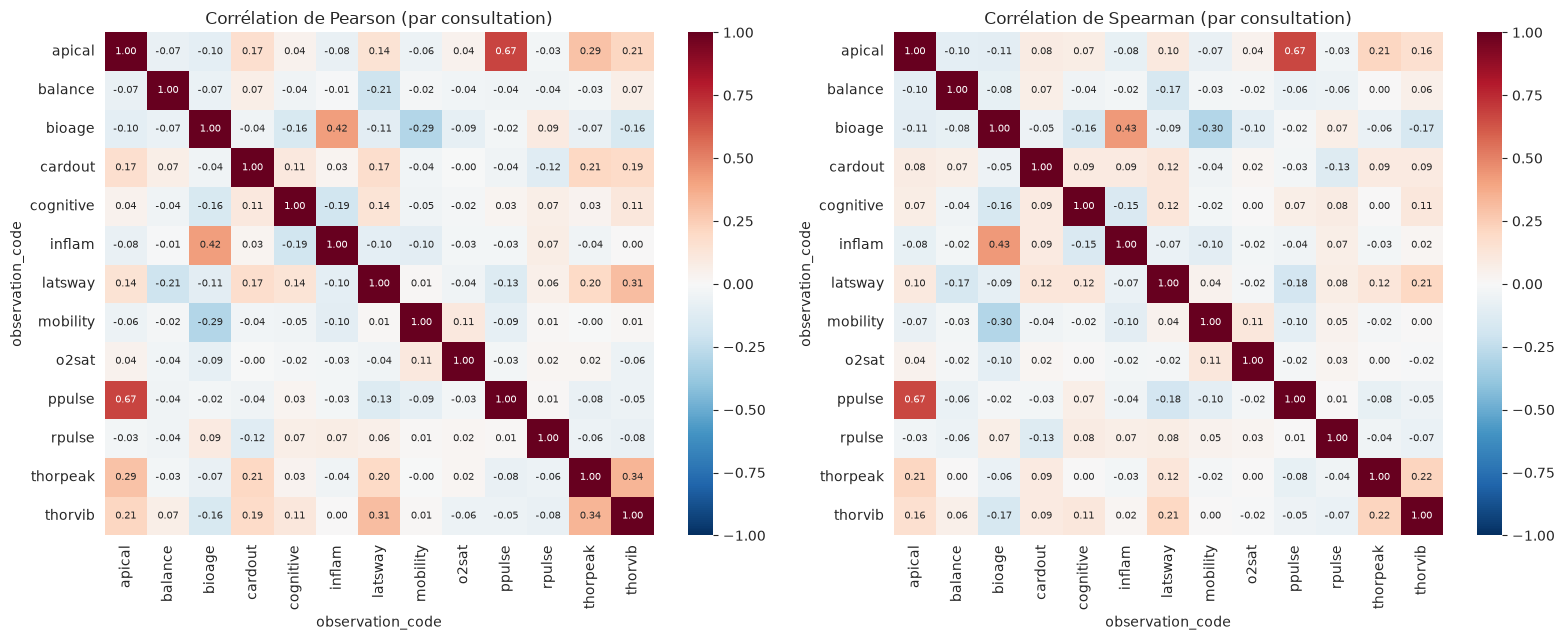

spearman  pearson
observation_code observation_code                   
apical           ppulse                0.67     0.67
bioage           inflam                0.43     0.42
                 mobility             -0.30    -0.29
thorpeak         thorvib               0.22     0.34
apical           thorpeak              0.21     0.29
latsway          thorvib               0.21     0.31
                 ppulse               -0.18    -0.13
balance          latsway              -0.17    -0.21

In [10]:
large = obs.pivot_table(index='encounter_number', columns='observation_code', values='numeric_value', aggfunc='mean')
# on garde les mesures présentes dans au moins 500 consultations pour avoir assez de paires
large = large.loc[:, large.notna().sum() >= 500]
pearson = large.corr(method='pearson')
spearman = large.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, m, t in zip(axes, [pearson, spearman], ['Pearson', 'Spearman']):
    sns.heatmap(m, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=ax)
    ax.set_title(f'Corrélation de {t} (par consultation)')
plt.tight_layout(); plt.show()

paires = (spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), 1)).stack()
          .rename('spearman').to_frame())
paires['pearson'] = pearson.where(np.triu(np.ones(pearson.shape, dtype=bool), 1)).stack()
paires = paires.reindex(paires.spearman.abs().sort_values(ascending=False).index)
paires.head(8).round(2)

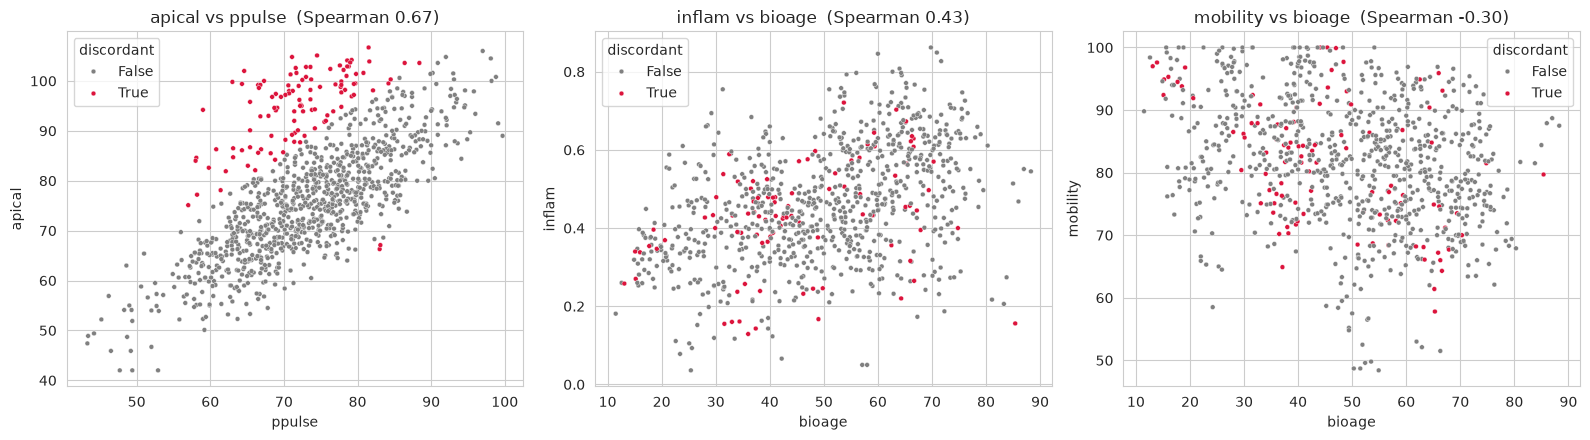

In [11]:
# Les trois paires les plus corrélées + l'écart apical - pouls périphérique coloré par interprétation
disc = obs[obs.interpretation_code == 'discordant'].encounter_number.unique()
large['discordant'] = large.index.isin(disc)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (x, y) in zip(axes, [('ppulse', 'apical'), ('bioage', 'inflam'), ('bioage', 'mobility')]):
    sns.scatterplot(data=large, x=x, y=y, hue='discordant', palette={False: 'grey', True: 'crimson'}, s=12, ax=ax)
    ax.set_title(f'{y} vs {x}  (Spearman {spearman.loc[x, y]:.2f})')
plt.tight_layout(); plt.show()

**Lecture**
- **Pouls périphérique / fréquence apicale** : la paire la plus corrélée (Spearman ≈ 0,67). Normal, les deux mesurent le même cœur. Mais le nuage montre un **second groupe décalé vers le haut** : ce sont les consultations `discordant` (en rouge), où la fréquence apicale dépasse le pouls d'environ 20 bpm. La corrélation globale masque donc une sous-population, qui n'est visible qu'en bivarié (même conclusion qu'au bloc 3).
- **Âge biologique / marqueur d'inflammation** (≈ 0,43) et **âge biologique / mobilité** (≈ −0,30) : corrélations modérées et plausibles cliniquement (on vieillit, l'inflammation monte, la mobilité baisse).
- `thorpeak`, `thorvib`, `latsway` et `apical` sont faiblement liés entre eux (0,2 à 0,3) : une petite structure commune, celle du profil « discordant » (bloc 7).
- Les mesures prises une seule fois par patient (`walkspd`, `cammatch`, `idcons`...) sont exclues de la matrice (moins de 500 consultations) ; `mobility` et `walkspd` sont fortement liés (Spearman ≈ 0,71 par patient).
- Pearson et Spearman donnent des valeurs proches, sauf pour les variables asymétriques (`thorpeak`, `thorvib`, `latsway`) où Pearson est plus élevé : quelques valeurs hautes communes tirent la corrélation linéaire.
- Toutes les autres paires sont faibles (|ρ| < 0,3).

**Corrélation n'est pas causalité.** Une corrélation dit que deux mesures varient ensemble, pas que l'une cause l'autre : ici apical et pouls périphérique ont une **cause commune** (le cœur), et âge biologique et inflammation dépendent tous deux de l'âge réel. Pour conclure à un effet (par exemple d'une procédure sur l'âge biologique), il faut une comparaison contrôlée, avant / après ou entre groupes : c'est ce qu'on fait au bloc 7.

## 6. Ce qu'on retient pour la suite
| Observation | Suite |
|---|---|
| Durées fixes 180 / 240 min, retard constant | Signature du protocole `MRP-42` (blocs 2-3) |
| Inscriptions toutes au 1er du mois | Artefact de génération : pas d'analyse au jour près |
| Pas de loi de puissance sur les comptages ; patients à 7-11 consultations | Ce sont les receveurs de `MRP-42` (bloc 4) |
| Sous-population décalée sur apical vs pouls | Observations `discordant` (blocs 3, 6, 7) |
| Asymétries de `latsway`, `thorpeak`, `cammatch`, `idcons` | Profil multivarié à tester (bloc 7) |